In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.Retrieval import Retrieval
# from src.utils.util import save_sensor_dict

In [3]:
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
TAU1D = EXPERIMENT / 'tau_1D'
r = Retrieval(EXPERIMENT)
r.load_retrieval()

In [4]:
tausA = np.linspace(0, 4.75, 20)
tausB = np.logspace(np.log10(5), 2, 40)
taus = np.append(tausA, tausB)
wavelength = 0.67
cb = 0.4
ct = 0.7
LUT_outfile = TAU1D / 'LUT_1Dtau.nc'
r.generate_1D_LUT(wavelength, taus, cb, ct, LUT_outfile)
outfile = TAU1D / 'tau1D.nc'
r.retrieve_1D_tau(outfile)

In [9]:
brf_ths = {
    'DF': 0.120,
    'CF': 0.076,
    'BF': 0.054,
    'AF': 0.044,
    'AN': 0.040,
    'AA': 0.045,
    'BA': 0.052,
    'CA': 0.068,
    'DA': 0.092
}
r.add_threshold_mask(r.obs, 'MISR', 'threshold_mask', 'brf', brf_ths)
r.add_threshold_mask(r.sensors_retrieval, 'MISR', 'tau_mask', 'optical_depth', 0.3)

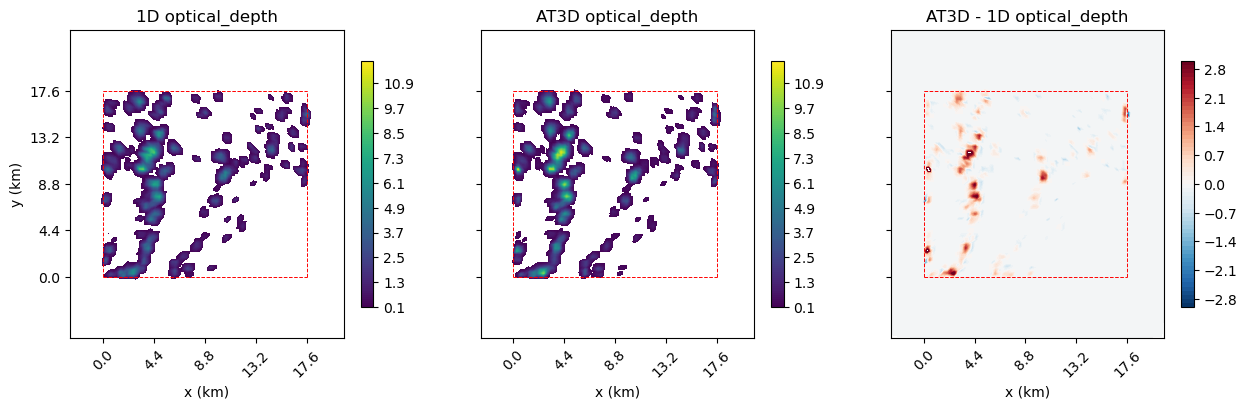

In [23]:
tau_kwargs = {
    'levels':np.arange(0.1,12.1,0.1)
}
tau_diff_kwargs = {
    'levels':np.arange(-3,3.02,0.1),
    'cmap':'RdBu_r'
}
f, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

sensor_i = 4
# mask_name = 'threshold_mask'
mask_name = 'tau_mask'
attr = 'optical_depth'

cam1D = r.obs['MISR']['sensor_list'][sensor_i]
cam3D = r.sensors_retrieval['MISR']['sensor_list'][sensor_i]
mask = r.masks['MISR']['sensor_list'][sensor_i][mask_name]

z1D = np.nan_to_num(cam1D[attr]) * mask
z3D = np.nan_to_num(cam3D[attr]) * mask

p1 = ax[0].tricontourf(cam1D.ray_x, cam1D.ray_y, z1D, **tau_kwargs)
p2 = ax[1].tricontourf(cam3D.ray_x, cam3D.ray_y, z3D, **tau_kwargs)
p3 = ax[2].tricontourf(cam1D.ray_x, cam1D.ray_y, z3D - z1D, **tau_diff_kwargs)

plt.colorbar(p1, ax=ax[0], shrink=0.8)
plt.colorbar(p2, ax=ax[1], shrink=0.8)
plt.colorbar(p3, ax=ax[2], shrink=0.8)

ax[0].set_title(f'1D {attr}')
ax[1].set_title(f'AT3D {attr}')
ax[2].set_title(f'AT3D - 1D {attr}')
ax[0].set_ylabel('y (km)')

ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
box_kwargs = {
    'c':'r',
    'ls': '--',
    'lw': 0.7
}
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [0, 0], **box_kwargs)
    a.plot([17.6, 17.6], [0, 17.6], **box_kwargs)
    a.plot([0, 17.6], [17.6, 17.6], **box_kwargs)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlabel('x (km)')
    # a.set_xlim([0,17.6])
    # a.set_ylim([0,17.6])

Text(0.5, 0, 'pct. difference optical_depth')

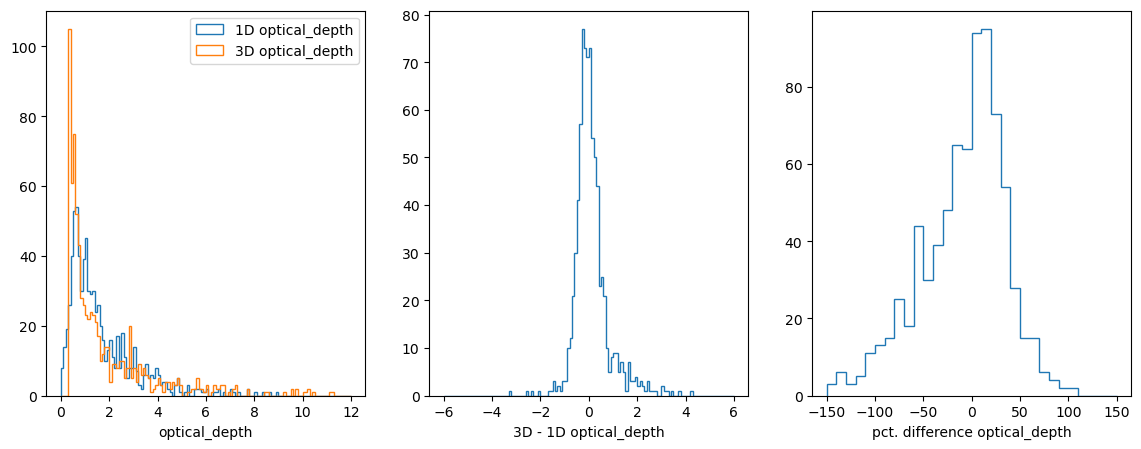

In [22]:
f, ax = plt.subplots(1, 3, figsize=(14, 5), sharex=False, sharey=False)

sensor_i = 4
# mask_name = 'threshold_mask'
mask_name = 'tau_mask'
attr = 'optical_depth'

cam1D = r.obs['MISR']['sensor_list'][sensor_i]
cam3D = r.sensors_retrieval['MISR']['sensor_list'][sensor_i]
mask = r.masks['MISR']['sensor_list'][sensor_i][mask_name]

z1D = np.nan_to_num(cam1D[attr])
z3D = np.nan_to_num(cam3D[attr])

hist_kwargs = {
    'bins':np.arange(0, 12.01, 0.1),
    'histtype':'step',
    'log': False,
    'density': False
}

ax[0].hist(z1D[mask==1], label=f'1D {attr}', **hist_kwargs)
ax[0].hist(z3D[mask==1], label=f'3D {attr}', **hist_kwargs)
ax[0].legend()
ax[0].set_xlabel(f'{attr}')

hist_kwargs['bins'] = np.arange(-6, 6.1, 0.1)
ax[1].hist(z3D[mask==1]-z1D[mask==1], label=f'3D - 1D {attr}', **hist_kwargs)
ax[1].set_xlabel(f'3D - 1D {attr}')

hist_kwargs['bins'] = np.arange(-150, 150.1, 10.0)
ax[2].hist(100*(z3D[mask==1]-z1D[mask==1]) / z3D[mask==1], label=f'pct. difference {attr}', **hist_kwargs)
ax[2].set_xlabel(f'pct. difference {attr}')